# 03 · Hardware performance and operating cycles

Real MetroPT-3 data. Run `python -m src.pipeline --csv data/raw/MetroPT3.csv` first to regenerate the analysis inputs. These notebooks also run directly on the aggregated outputs included in the delivery.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import ANALOG, DIGITAL
OUT = ROOT / 'data/processed'
x = pd.read_parquet(OUT / 'monitoring_5min.parquet')
events = pd.read_csv(ROOT / 'data/reference/failure_events.csv', parse_dates=['start','end'])
quality = json.loads((ROOT / 'reports/data_quality.json').read_text())
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 30)


## Performance by operating state
`DV_eletric` indicates loaded operation. For five-minute bins, values near one indicate mostly loaded time and values near zero indicate mostly unloaded/off time. Mixed bins are retained as a separate state. These groups are analytical summaries, not a calibrated state estimator.

TP2                                      TP3            \
                     mean       std       min        max      mean       std   
state                                                                          
mixed            3.346189  1.202875 -0.020000   8.687806  9.102567  0.515753   
mostly_loaded    8.016722  1.542076 -0.014533  10.234129  8.326400  0.991745   
mostly_unloaded  0.021679  0.151813 -0.019667   1.376867  9.007708  0.456859   

                                            H1                               \
                      min        max      mean       std     min        max   
state                                                                         
mixed            6.711419  10.161667  5.701461  1.249839 -0.0140  10.036000   
mostly_loaded    1.561800  10.127533  0.002765  0.081769 -0.0152   1.009267   
mostly_unloaded  8.100933  10.140000  8.958311  0.471138  7.1666  10.144000   

                DV_pressure                               Reservoirs  \
                       mean       std       min       max       mean   
state                                                                  
mixed              0.002627  0.068063 -0.030516  1.249667   9.102084   
mostly_loaded      1.476681  0.743177 -0.028643  2.507548   8.327394   
mostly_unloaded   -0.019519  0.010523 -0.030867  0.285600   9.008762   

                                               Oil_temperature            \
                      std       min        max            mean       std   
state                                                                      
mixed            0.514890  6.713161  10.158667       63.672067  5.836075   
mostly_loaded    0.992072  1.554000  10.122733       73.377647  6.806683   
mostly_unloaded  0.456269  8.106267  10.138000       61.472808  5.542644   

                                      Motor_current                      \
                       min        max          mean       std       min   
state                                                                     
mixed            35.745000  80.688333      3.447455  1.197071  0.021417   
mostly_loaded    24.091964  88.629167      5.443487  0.894800  0.020446   
mostly_unloaded  36.389516  76.151667      1.217236  1.513568  0.022500   

                           
                      max  
state                      
mixed            5.766613  
mostly_loaded    6.092583  
mostly_unloaded  4.251667

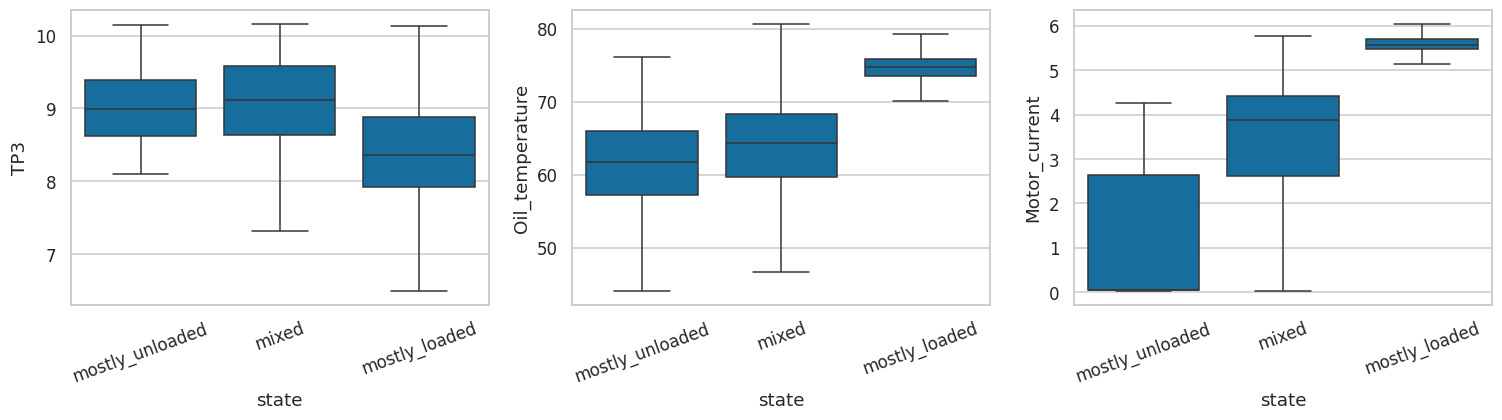

In [2]:
valid=x.loc[x.quality_eligible].copy()
valid['state']=np.select([valid.load_fraction.ge(.9),valid.load_fraction.le(.1)],['mostly_loaded','mostly_unloaded'],default='mixed')
display(valid.groupby('state')[ANALOG].agg(['mean','std','min','max']))
fig,axs=plt.subplots(1,3,figsize=(14,4))
for ax,c in zip(axs,['TP3','Oil_temperature','Motor_current']):
    sns.boxplot(data=valid,x='state',y=c,showfliers=False,ax=ax)
    ax.tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.show()


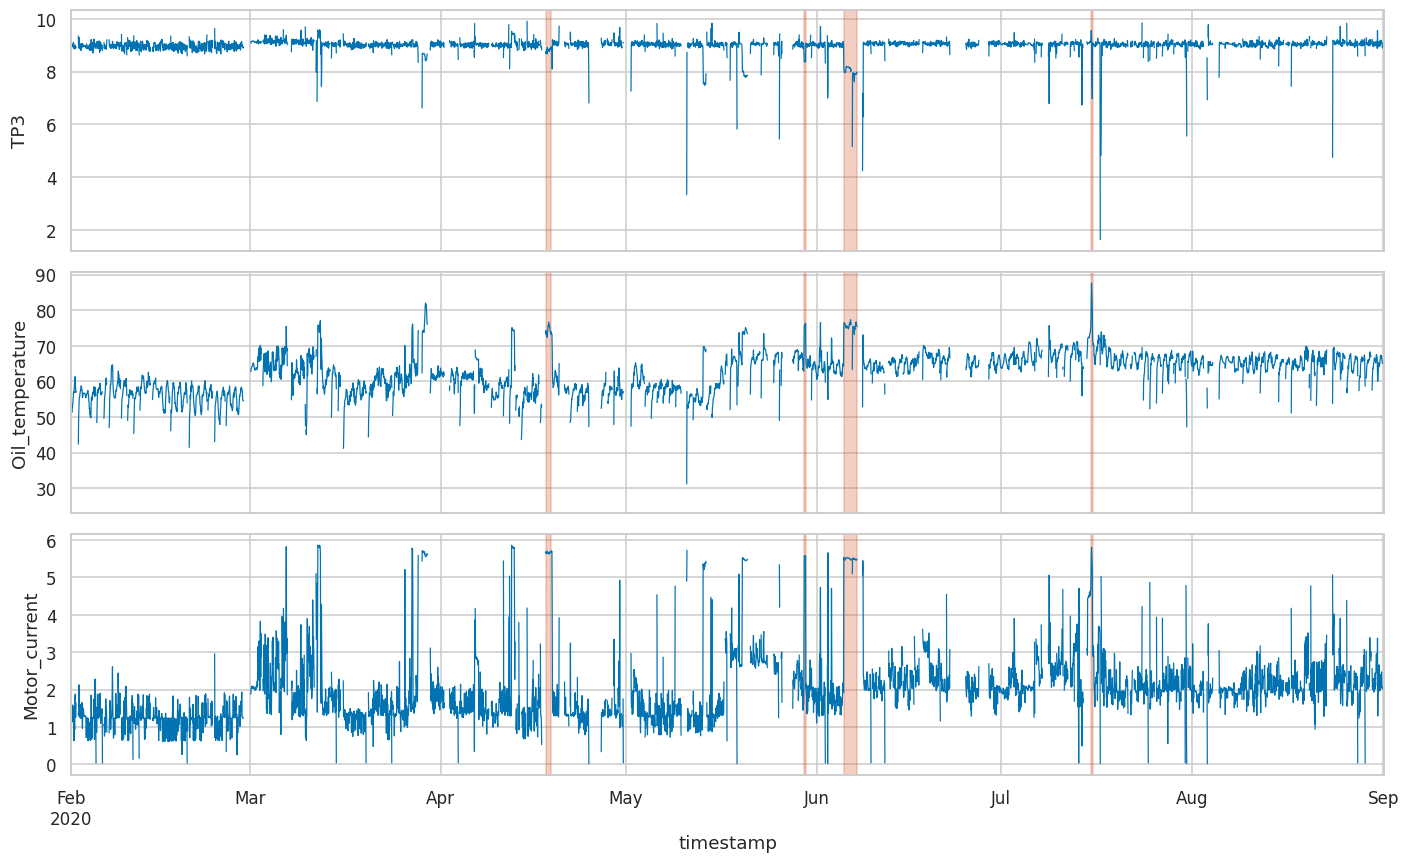

In [3]:
hourly=valid[ANALOG+['load_fraction','pressure_gap']].resample('1h').mean()
fig,axs=plt.subplots(3,1,figsize=(13,8),sharex=True)
for ax,c in zip(axs,['TP3','Oil_temperature','Motor_current']):
    hourly[c].plot(ax=ax,lw=.8)
    for e in events.itertuples(): ax.axvspan(e.start,e.end,color='#d95d39',alpha=.3)
    ax.set_ylabel(c)
plt.tight_layout(); plt.show()


## Cycle durations
A cycle here is a contiguous digital-state run. Runs at the dataset boundaries and telemetry gaps are censored. A long loaded run may be an investigation signal, but does not itself confirm a leak.

,count,mean,std,min,50%,90%,95%,99%,max
load_state,,,,,,,,,
0.0,15457.0,13.065693,10.831300,0.166667,14.033333,27.916667,31.550000,37.249333,45.583333
1.0,15539.0,2.036518,8.949057,0.166667,2.150000,2.650000,2.816667,4.133333,705.650000


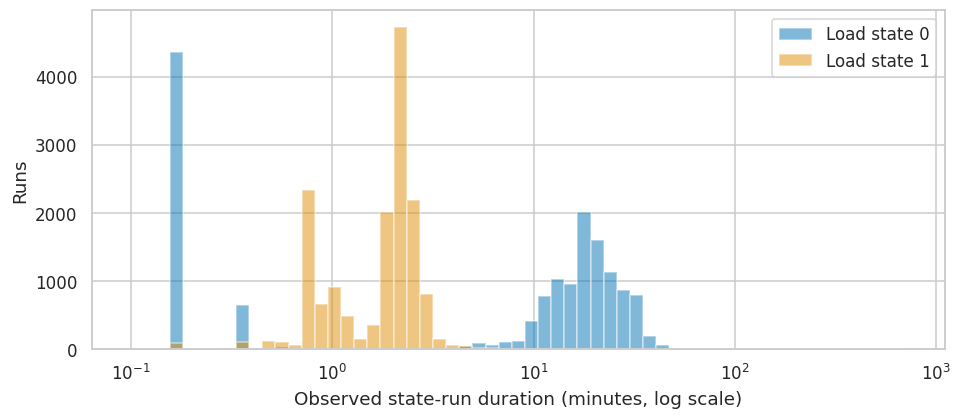

In [4]:
cycles=pd.read_csv(OUT/'operating_cycles.csv',parse_dates=['start','end'])
complete=cycles.loc[~cycles.censored].copy()
complete['duration_minutes']=complete.duration_seconds/60
display(complete.groupby('load_state').duration_minutes.describe(percentiles=[.5,.9,.95,.99]))
fig,ax=plt.subplots(figsize=(10,4))
for state,group in complete.groupby('load_state'):
    ax.hist(group.duration_minutes,bins=np.geomspace(.1,max(1,complete.duration_minutes.max()),60),alpha=.5,label=f'Load state {state:g}')
ax.set(xscale='log',xlabel='Observed state-run duration (minutes, log scale)',ylabel='Runs'); ax.legend(); plt.show()


,load_fraction,TP3,Motor_current
timestamp,,,
0,0.165907,8.978246,2.089869
1,0.171590,8.968535,2.035591
2,0.158031,8.959512,1.921297
3,0.145741,8.999538,1.947262
4,0.149006,8.992055,1.953637
5,0.149017,8.989648,2.021845
6,0.145446,8.994830,2.047795
7,0.156479,9.021788,2.132109
8,0.152042,9.005998,2.055443


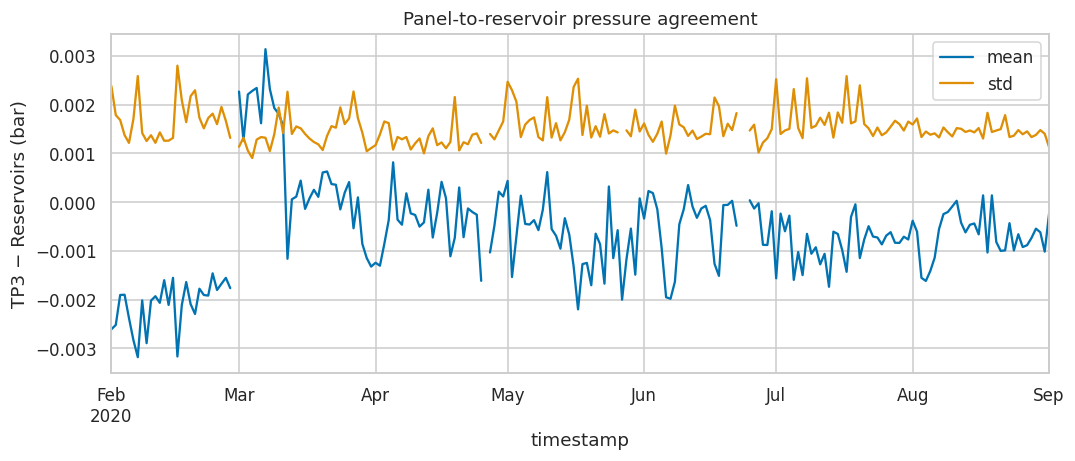

In [5]:
display(valid.groupby(valid.index.hour)[['load_fraction','TP3','Motor_current']].mean())
fig,ax=plt.subplots(figsize=(11,4)); valid.pressure_gap.resample('1D').agg(['mean','std']).plot(ax=ax)
ax.set(title='Panel-to-reservoir pressure agreement',ylabel='TP3 − Reservoirs (bar)'); plt.show()


## Engineering interpretation
Review state mix before comparing overall means. Panel/reservoir disagreement can justify checking sensors, plumbing and calibration, but this analysis does not identify a component fault conclusively. Cycle summaries include flatline-contaminated runs unless censored; compare their dates with the telemetry-quality episode table before using long-run tails.